# Live Deployment Link

## **Web app: https://zainaftab-diamond-price.streamlit.app**

| | |
|---|---|
| **Course** | AIC354 Machine Learning Fundamentals |
| **Assignment** | 3: Applying, Evaluating and Comparing Multiple ML Algorithms on a Large Real-World Dataset |
| **Student** | Zain Aftab (FA24-BSE-155) |
| **Instructor** | Dr. Rao Muhammad Adeel Nawab |

# Diamond Price Prediction System – 10-Fold Cross Validation (Full Dataset)

## Setup: Running This Notebook on Google Colab

No installation is needed. Google Colab already has every library this notebook uses.

1. Go to **https://colab.research.google.com** and sign in with a Google account.
2. Click **File → Upload notebook** and choose this `.ipynb` file.
3. Click **Runtime → Run all**.
4. When **Step 2.1** runs, a **"Choose Files"** button appears below that cell. Click it and select **`diamonds.csv`** from your computer. The notebook continues automatically after the upload.

> **Note:** Colab deletes uploaded files when the runtime is reset or disconnected. If you get a *"file not found"* error, run Step 2.1 again and re-upload `diamonds.csv`.

---

## Introduction

##### **Definition** A regression ML task that predicts the price of a diamond (in US dollars) from its physical and quality features: carat weight, cut, colour, clarity, depth percentage, table width and its length, width and depth in millimetres.
##### **Application** Online jewellery stores, diamond wholesalers, insurance valuation, pawn shops and buyers who want to check whether an asking price is fair.

### Why This Problem

This problem is similar to the Car Price Prediction System: both predict the **price of a product** from its **specifications**, and both mix **numeric** features (carat, size) with **categorical** features (cut, colour, clarity), so the same pre-processing and evaluation approach applies.

### Dataset

| | |
|---|---|
| **Name** | Diamonds dataset |
| **Original source** | Hadley Wickham, *ggplot2* R package (`diamonds` data set) |
| **Download link used** | https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv |
| **Size** | 53,940 diamonds, 10 attributes (9 inputs + price) |
| **Output** | `price` in US dollars ($326 to $18,823) |

### Aim of This Notebook

> **Which of 5 regression algorithms predicts diamond prices best, and how sure can we be about that answer?**

To answer it fairly we use **10-Fold Cross Validation** on the **full dataset** and compare the algorithms using **Root Mean Squared Error (RMSE)**, exactly as in the Car Price Prediction System. As the assignment requires, all 5 algorithms are **different** from the 5 used in the Car Price notebook (Linear Regression, KNN, Decision Tree, Random Forest and Gradient Boosting).

### What is K-Fold Cross Validation?

1. Shuffle the data and split it into **K equal parts (folds)**.
2. Train the model on **K−1 folds** and test it on the **remaining fold**.
3. Repeat **K times**, so that **every fold is used as the test set exactly once**.
4. Report the **average** score over the K rounds (and the standard deviation, to show how much it varies).

With **K = 10** on the **full dataset (~53,800 diamonds)**, each test fold has about 5,380 diamonds and each training set has about 48,400 diamonds.

# Code – Diamond Price Prediction System
## Step 1: Import Libraries

In [1]:
# --- Core Python Libraries ---
import os
import time

import joblib
import numpy as np
import pandas as pd

# --- Machine Learning (scikit-learn) ---
import sklearn
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# --- The 5 Regression Algorithms (none of them was used in the Car Price notebook) ---
from sklearn.linear_model import Ridge
from sklearn.svm import LinearSVR
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import ExtraTreesRegressor, AdaBoostRegressor

# --- Visualization ---
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

# --- Progress bar (shows elapsed and remaining time) ---
from tqdm import tqdm

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

print("Library versions used in this run:")
print(f"  NumPy        : {np.__version__}")
print(f"  Pandas       : {pd.__version__}")
print(f"  scikit-learn : {sklearn.__version__}")
print(f"  Matplotlib   : {matplotlib.__version__}")

Library versions used in this run:
  NumPy        : 2.5.3
  Pandas       : 3.0.5
  scikit-learn : 1.9.1
  Matplotlib   : 3.11.2


# Step 2: Load Data
## Step 2.1: Upload the Dataset (Google Colab)

When this cell runs in Google Colab, a **"Choose Files"** button appears. Select **`diamonds.csv`**.

If the file is already present, the upload is skipped. If the file is missing and you are **not** in Colab, it is downloaded from the link given in the Introduction.

In [2]:
DATA_FILE = "diamonds.csv"
DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv"

# google.colab is only available inside Google Colab
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.exists(DATA_FILE):
    print(f"Please click 'Choose Files' and select '{DATA_FILE}' ...")
    uploaded = files.upload()
    uploaded_name = list(uploaded.keys())[0]
    if uploaded_name != DATA_FILE:          # e.g. 'diamonds (1).csv'
        os.rename(uploaded_name, DATA_FILE)

if not os.path.exists(DATA_FILE):
    print("Downloading the dataset ...")
    pd.read_csv(DATA_URL).to_csv(DATA_FILE, index=False)

print(f"'{DATA_FILE}' is ready to use.")

'diamonds.csv' is ready to use.


## Step 2.2: Read the Dataset

This notebook uses **all** the diamonds in the dataset.

In [3]:
diamonds = pd.read_csv(DATA_FILE)

print(f"Loaded dataset: {diamonds.shape[0]:,} diamonds")
diamonds.head()

Loaded dataset: 53,940 diamonds


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.50,55.00,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.80,61.00,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.90,65.00,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.40,58.00,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.30,58.00,335,4.34,4.35,2.75


# Step 3: Understand and Pre-process Data
## Step 3.1: Understand Data

| Attribute | Meaning |
|---|---|
| `carat` | Weight of the diamond (1 carat = 0.2 g) |
| `cut` | Quality of the cut: Fair, Good, Very Good, Premium, Ideal |
| `color` | Colour grade from D (best, colourless) to J (worst) |
| `clarity` | How clear the diamond is: I1 (worst), SI2, SI1, VS2, VS1, VVS2, VVS1, IF (best) |
| `depth` | Total depth percentage = z / mean(x, y) × 100 |
| `table` | Width of the top of the diamond relative to its widest point (%) |
| `x`, `y`, `z` | Length, width and depth in millimetres |
| `price` | **Output**: price in US dollars |

In [4]:
"""
Purpose of this section:
1. Print the names of all attributes (columns).
2. Show the total number of instances (rows).
3. Show how many values are missing in each attribute.
"""
print("\nAttributes in Data:")
print("===================\n")
print(list(diamonds.columns))

print("\nNumber of Instances in Data:")
print("============================\n")
print(len(diamonds))

print("\nMissing Values in Each Attribute:")
print("=================================\n")
missing = diamonds.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values (empty cells)")

print("\nDiamonds with a size of 0 mm (impossible, so really missing):")
print("============================================================\n")
print((diamonds[["x", "y", "z"]] == 0).sum())


Attributes in Data:

['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y', 'z']

Number of Instances in Data:

53940

Missing Values in Each Attribute:

No missing values (empty cells)

Diamonds with a size of 0 mm (impossible, so really missing):

x     8
y     7
z    20
dtype: int64


### Understanding the Output (Price)

Before choosing an evaluation measure, we look at the **range of the output**.

In [5]:
price_summary = diamonds["price"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
price_summary.to_frame(name="Price ($)")

,Price ($)
count,"53,940.00"
mean,"3,932.80"
std,"3,989.44"
min,326.00
25%,950.00
50%,"2,401.00"
75%,"5,324.25"
95%,"13,107.10"
99%,"17,378.22"
max,"18,823.00"


> **Why this matters for RMSE:** RMSE squares each error, so large errors on expensive diamonds count much more than small errors on cheap ones. Unlike the car data, diamond prices have **no extreme outliers**: the most expensive diamond costs about $18,800, so a few items cannot dominate the RMSE as the $2,000,000 cars did. We therefore expect the RMSE to be **much more stable across folds**.

## Step 3.2: Pre-process Data

In [6]:
"""
Pre-processing steps:
1. Remove duplicate rows. A duplicate could appear in BOTH the training folds and the
   test fold, so the model would be tested on a diamond it has already seen.
2. A size of 0 mm in x, y or z is impossible: it means the value was not recorded.
   We mark it as missing (NaN). It is filled inside the pipeline in Step 5, using only
   the training folds, so no information leaks from the test fold.
"""
rows_before = len(diamonds)
diamonds = diamonds.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed: {rows_before - len(diamonds):,}")
print(f"Instances remaining   : {len(diamonds):,}")

for column in ["x", "y", "z"]:
    diamonds.loc[diamonds[column] == 0, column] = np.nan
print("\nZero sizes replaced with missing values:", diamonds[["x", "y", "z"]].isnull().sum().to_dict())

Duplicate rows removed: 146
Instances remaining   : 53,794

Zero sizes replaced with missing values: {'x': 7, 'y': 6, 'z': 19}


# Step 4: Feature Extraction

We use **all 9 input attributes**: 6 numeric and 3 categorical. Then we separate the **input (X)** from the **output (y)**.

In [7]:
numeric_features = ["carat", "depth", "table", "x", "y", "z"]
categorical_features = ["cut", "color", "clarity"]
target = "price"

X = diamonds[numeric_features + categorical_features]
y = diamonds[target]

print(f"Input features (X): {X.shape[1]} columns -> {list(X.columns)}")
print(f"Output (y)        : {target}")
print(f"Number of diamonds: {len(X):,}")
X.head()

Input features (X): 9 columns -> ['carat', 'depth', 'table', 'x', 'y', 'z', 'cut', 'color', 'clarity']
Output (y)        : price
Number of diamonds: 53,794


,carat,depth,table,x,y,z,cut,color,clarity
0,0.23,61.50,55.00,3.95,3.98,2.43,Ideal,E,SI2
1,0.21,59.80,61.00,3.89,3.84,2.31,Premium,E,SI1
2,0.23,56.90,65.00,4.05,4.07,2.31,Good,E,VS1
3,0.29,62.40,58.00,4.20,4.23,2.63,Premium,I,VS2
4,0.31,63.30,58.00,4.34,4.35,2.75,Good,J,SI2


# Step 5: Build the Pre-processing Pipeline

| Feature type | Step | Why |
|---|---|---|
| Numeric | **Fill missing values** with the median | Algorithms cannot handle empty values |
| Numeric | **Standard scaling** (mean 0, std 1) | Ridge, Linear SVR and the Neural Network are sensitive to the scale of each feature |
| Categorical | **One-hot encoding** | Turns text categories into 0/1 columns without inventing a fake order |

The pre-processing is placed **inside the pipeline**, so in every round of cross validation it is fitted on the training folds only, which prevents **data leakage**.

In [8]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

print("Pre-processing pipeline created:")
preprocessor

Pre-processing pipeline created:


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

# Step 6: Define the 5 Regression Algorithms

None of these algorithms was used in the Car Price Prediction System. They cover five different families of learning methods:

| # | Algorithm | Family | How it predicts a price |
|---|---|---|---|
| 1 | **Ridge Regression** | Linear model with regularisation | A weighted sum of the features, like Linear Regression, but with a penalty that keeps the weights small and reduces overfitting |
| 2 | **Linear Support Vector Regression (Linear SVR)** | Support vector machine | Fits a straight line that ignores errors smaller than a margin and minimises the larger ones |
| 3 | **Neural Network (MLP Regressor)** | Artificial neural network | Passes the features through a hidden layer of 100 neurons that can learn non-linear patterns |
| 4 | **Extra Trees (Extremely Randomised Trees)** | Ensemble, bagging-style | Builds 100 trees with **random split points** and averages them; more random than Random Forest, so it is faster and often generalises well |
| 5 | **AdaBoost** | Ensemble, boosting | Builds small trees one after another and gives more weight to the diamonds that previous trees predicted badly |

Default settings are used, except for three settings that are needed to make the run work or the model usable:

- **Linear SVR**: `max_iter=5000`, because the default 1,000 iterations do not converge on this data.
- **Neural Network**: `max_iter=500` with `early_stopping=True`, so it trains until the score on a held-out 10% of the training folds stops improving.
- **Extra Trees**: `min_samples_leaf=5`. A fully grown Extra Trees model on 53,800 diamonds is about **680 MB**, too big to deploy. With at least 5 diamonds in each leaf it is about **34 MB** and, in our tests, slightly **more** accurate.

`random_state=42` makes the results reproducible.

In [9]:
algorithms = {
    "Ridge Regression": Ridge(),
    "Linear SVR": LinearSVR(max_iter=5000, random_state=42),
    "Neural Network (MLP)": MLPRegressor(max_iter=500, early_stopping=True, random_state=42),
    "Extra Trees": ExtraTreesRegressor(n_estimators=100, min_samples_leaf=5, random_state=42, n_jobs=-1),
    "AdaBoost": AdaBoostRegressor(random_state=42),
}

print("Algorithms to compare:")
for number, name in enumerate(algorithms, start=1):
    print(f"  {number}. {name}")

Algorithms to compare:
  1. Ridge Regression
  2. Linear SVR
  3. Neural Network (MLP)
  4. Extra Trees
  5. AdaBoost


# Step 7: Set Up 10-Fold Cross Validation
## Step 7.1: Create the K-Fold Splitter

- `n_splits=10`: split the data into 10 folds
- `shuffle=True`: the dataset is sorted by price, so without shuffling a fold could contain only cheap diamonds
- `random_state=42`: the **same folds are used for all 5 algorithms**, which makes the comparison fair

In [10]:
K = 10
kfold = KFold(n_splits=K, shuffle=True, random_state=42)
print(f"{K}-Fold Cross Validation created (shuffle=True, random_state=42)")

10-Fold Cross Validation created (shuffle=True, random_state=42)


## Step 7.2: Inspect the Folds

In [11]:
fold_sizes = []
for fold_number, (train_index, test_index) in enumerate(kfold.split(X), start=1):
    fold_sizes.append({
        "Fold (Round)": fold_number,
        "Training Diamonds": len(train_index),
        "Testing Diamonds": len(test_index),
        "Avg Price of Test Diamonds ($)": y.iloc[test_index].mean(),
        "Most Expensive Test Diamond ($)": y.iloc[test_index].max(),
    })

fold_sizes_table = pd.DataFrame(fold_sizes).set_index("Fold (Round)")
fold_sizes_table

,Training Diamonds,Testing Diamonds,Avg Price of Test Diamonds ($),Most Expensive Test Diamond ($)
Fold (Round),,,,
1,48414,5380,"3,862.60",18791
2,48414,5380,"3,908.42",18779
3,48414,5380,"3,875.83",18818
4,48414,5380,"3,965.32",18823
5,48415,5379,"3,922.57",18787
6,48415,5379,"3,921.42",18797
7,48415,5379,"3,914.45",18803
8,48415,5379,"4,046.61",18795
9,48415,5379,"3,862.48",18795


Every fold has almost the same average price and a most expensive diamond close to $18,800, so the folds are **balanced**. This is very different from the car data, where single cars worth over $1 million made some folds much harder than others.

# Step 8: Run 10-Fold Cross Validation for All 5 Algorithms

For each algorithm we build a pipeline (**pre-processing → algorithm**). Then, for each of the 10 folds, we make a **fresh copy** of the pipeline, **train** it on the training folds, **predict** the test fold and calculate the **RMSE**.

The progress bar has **5 × 10 = 50 steps** and shows the elapsed and the estimated remaining time.

> ⏱ **This step takes several minutes in Colab.** The Neural Network and Extra Trees are the slowest.

In [12]:
fold_rmse = {}
training_time = {}

folds = list(kfold.split(X))
total_steps = len(algorithms) * K

with tqdm(total=total_steps, unit="fold") as progress_bar:
    for name, algorithm in algorithms.items():
        model = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", algorithm),
        ])

        scores = []
        start = time.time()
        for fold_number, (train_index, test_index) in enumerate(folds, start=1):
            progress_bar.set_description(f"{name}, fold {fold_number}/{K}")

            fold_model = clone(model)
            fold_model.fit(X.iloc[train_index], y.iloc[train_index])
            predictions = fold_model.predict(X.iloc[test_index])
            rmse = np.sqrt(mean_squared_error(y.iloc[test_index], predictions))
            scores.append(rmse)

            progress_bar.update(1)

        training_time[name] = time.time() - start
        fold_rmse[name] = np.array(scores)
        tqdm.write(f"{name:<22} -> mean RMSE = ${fold_rmse[name].mean():>9,.2f}   ({training_time[name]:.1f} s)")

    progress_bar.set_description("Done")

print(f"\n{K}-fold cross validation completed for all {len(algorithms)} algorithms.")

  0%|          | 0/50 [00:00<?, ?fold/s]

Ridge Regression, fold 1/10:   0%|          | 0/50 [00:00<?, ?fold/s]

Ridge Regression, fold 1/10:   2%|▏         | 1/50 [00:00<00:07,  6.17fold/s]

Ridge Regression, fold 2/10:   2%|▏         | 1/50 [00:00<00:07,  6.17fold/s]

Ridge Regression, fold 2/10:   4%|▍         | 2/50 [00:00<00:07,  6.40fold/s]

Ridge Regression, fold 3/10:   4%|▍         | 2/50 [00:00<00:07,  6.40fold/s]

Ridge Regression, fold 3/10:   6%|▌         | 3/50 [00:00<00:06,  6.74fold/s]

Ridge Regression, fold 4/10:   6%|▌         | 3/50 [00:00<00:06,  6.74fold/s]

Ridge Regression, fold 4/10:   8%|▊         | 4/50 [00:00<00:06,  6.78fold/s]

Ridge Regression, fold 5/10:   8%|▊         | 4/50 [00:00<00:06,  6.78fold/s]

Ridge Regression, fold 5/10:  10%|█         | 5/50 [00:00<00:06,  6.81fold/s]

Ridge Regression, fold 6/10:  10%|█         | 5/50 [00:00<00:06,  6.81fold/s]

Ridge Regression, fold 6/10:  12%|█▏        | 6/50 [00:00<00:06,  6.66fold/s]

Ridge Regression, fold 7/10:  12%|█▏        | 6/50 [00:00<00:06,  6.66fold/s]

Ridge Regression, fold 7/10:  14%|█▍        | 7/50 [00:01<00:06,  6.82fold/s]

Ridge Regression, fold 8/10:  14%|█▍        | 7/50 [00:01<00:06,  6.82fold/s]

Ridge Regression, fold 8/10:  16%|█▌        | 8/50 [00:01<00:06,  6.80fold/s]

Ridge Regression, fold 9/10:  16%|█▌        | 8/50 [00:01<00:06,  6.80fold/s]

Ridge Regression, fold 9/10:  18%|█▊        | 9/50 [00:01<00:06,  6.63fold/s]

Ridge Regression, fold 10/10:  18%|█▊        | 9/50 [00:01<00:06,  6.63fold/s]

Ridge Regression, fold 10/10:  20%|██        | 10/50 [00:01<00:05,  6.72fold/s]

Ridge Regression, fold 10/10:  20%|██        | 10/50 [00:01<00:05,  6.72fold/s]

Linear SVR, fold 1/10:  20%|██        | 10/50 [00:01<00:05,  6.72fold/s]       

Linear SVR, fold 1/10:  22%|██▏       | 11/50 [00:01<00:06,  6.42fold/s]

Linear SVR, fold 2/10:  22%|██▏       | 11/50 [00:01<00:06,  6.42fold/s]

Ridge Regression       -> mean RMSE = $ 1,136.38   (1.5 s)


Linear SVR, fold 2/10:  24%|██▍       | 12/50 [00:01<00:06,  6.16fold/s]

Linear SVR, fold 3/10:  24%|██▍       | 12/50 [00:01<00:06,  6.16fold/s]

Linear SVR, fold 3/10:  26%|██▌       | 13/50 [00:02<00:06,  5.82fold/s]

Linear SVR, fold 4/10:  26%|██▌       | 13/50 [00:02<00:06,  5.82fold/s]

Linear SVR, fold 4/10:  28%|██▊       | 14/50 [00:02<00:06,  5.61fold/s]

Linear SVR, fold 5/10:  28%|██▊       | 14/50 [00:02<00:06,  5.61fold/s]

Linear SVR, fold 5/10:  30%|███       | 15/50 [00:02<00:06,  5.48fold/s]

Linear SVR, fold 6/10:  30%|███       | 15/50 [00:02<00:06,  5.48fold/s]

Linear SVR, fold 6/10:  32%|███▏      | 16/50 [00:02<00:06,  5.57fold/s]

Linear SVR, fold 7/10:  32%|███▏      | 16/50 [00:02<00:06,  5.57fold/s]

Linear SVR, fold 7/10:  34%|███▍      | 17/50 [00:02<00:06,  5.38fold/s]

Linear SVR, fold 8/10:  34%|███▍      | 17/50 [00:02<00:06,  5.38fold/s]

Linear SVR, fold 8/10:  36%|███▌      | 18/50 [00:02<00:05,  5.56fold/s]

Linear SVR, fold 9/10:  36%|███▌      | 18/50 [00:02<00:05,  5.56fold/s]

Linear SVR, fold 9/10:  38%|███▊      | 19/50 [00:03<00:05,  5.62fold/s]

Linear SVR, fold 10/10:  38%|███▊      | 19/50 [00:03<00:05,  5.62fold/s]

Linear SVR, fold 10/10:  40%|████      | 20/50 [00:03<00:05,  5.59fold/s]

Linear SVR, fold 10/10:  40%|████      | 20/50 [00:03<00:05,  5.59fold/s]

Neural Network (MLP), fold 1/10:  40%|████      | 20/50 [00:03<00:05,  5.59fold/s]

Linear SVR             -> mean RMSE = $ 1,468.52   (1.8 s)


Neural Network (MLP), fold 1/10:  42%|████▏     | 21/50 [00:27<03:32,  7.34s/fold]

Neural Network (MLP), fold 2/10:  42%|████▏     | 21/50 [00:27<03:32,  7.34s/fold]

Neural Network (MLP), fold 2/10:  44%|████▍     | 22/50 [00:51<05:43, 12.29s/fold]

Neural Network (MLP), fold 3/10:  44%|████▍     | 22/50 [00:51<05:43, 12.29s/fold]

Neural Network (MLP), fold 3/10:  46%|████▌     | 23/50 [01:15<07:07, 15.83s/fold]

Neural Network (MLP), fold 4/10:  46%|████▌     | 23/50 [01:15<07:07, 15.83s/fold]

Neural Network (MLP), fold 4/10:  48%|████▊     | 24/50 [01:37<07:45, 17.90s/fold]

Neural Network (MLP), fold 5/10:  48%|████▊     | 24/50 [01:37<07:45, 17.90s/fold]

Neural Network (MLP), fold 5/10:  50%|█████     | 25/50 [02:03<08:25, 20.20s/fold]

Neural Network (MLP), fold 6/10:  50%|█████     | 25/50 [02:03<08:25, 20.20s/fold]

Neural Network (MLP), fold 6/10:  52%|█████▏    | 26/50 [02:31<09:00, 22.51s/fold]

Neural Network (MLP), fold 7/10:  52%|█████▏    | 26/50 [02:31<09:00, 22.51s/fold]

Neural Network (MLP), fold 7/10:  54%|█████▍    | 27/50 [03:08<10:19, 26.94s/fold]

Neural Network (MLP), fold 8/10:  54%|█████▍    | 27/50 [03:08<10:19, 26.94s/fold]

Neural Network (MLP), fold 8/10:  56%|█████▌    | 28/50 [03:57<12:17, 33.50s/fold]

Neural Network (MLP), fold 9/10:  56%|█████▌    | 28/50 [03:57<12:17, 33.50s/fold]

Neural Network (MLP), fold 9/10:  58%|█████▊    | 29/50 [04:17<10:16, 29.35s/fold]

Neural Network (MLP), fold 10/10:  58%|█████▊    | 29/50 [04:17<10:16, 29.35s/fold]

Neural Network (MLP), fold 10/10:  60%|██████    | 30/50 [04:44<09:35, 28.78s/fold]

Neural Network (MLP), fold 10/10:  60%|██████    | 30/50 [04:44<09:35, 28.78s/fold]

Extra Trees, fold 1/10:  60%|██████    | 30/50 [04:44<09:35, 28.78s/fold]          

Neural Network (MLP)   -> mean RMSE = $   694.52   (281.3 s)


Extra Trees, fold 1/10:  62%|██████▏   | 31/50 [04:50<06:57, 21.95s/fold]

Extra Trees, fold 2/10:  62%|██████▏   | 31/50 [04:50<06:57, 21.95s/fold]

Extra Trees, fold 2/10:  64%|██████▍   | 32/50 [04:57<05:11, 17.29s/fold]

Extra Trees, fold 3/10:  64%|██████▍   | 32/50 [04:57<05:11, 17.29s/fold]

Extra Trees, fold 3/10:  66%|██████▌   | 33/50 [05:04<04:01, 14.19s/fold]

Extra Trees, fold 4/10:  66%|██████▌   | 33/50 [05:04<04:01, 14.19s/fold]

Extra Trees, fold 4/10:  68%|██████▊   | 34/50 [05:10<03:10, 11.93s/fold]

Extra Trees, fold 5/10:  68%|██████▊   | 34/50 [05:10<03:10, 11.93s/fold]

Extra Trees, fold 5/10:  70%|███████   | 35/50 [05:17<02:33, 10.25s/fold]

Extra Trees, fold 6/10:  70%|███████   | 35/50 [05:17<02:33, 10.25s/fold]

Extra Trees, fold 6/10:  72%|███████▏  | 36/50 [05:24<02:10,  9.31s/fold]

Extra Trees, fold 7/10:  72%|███████▏  | 36/50 [05:24<02:10,  9.31s/fold]

Extra Trees, fold 7/10:  74%|███████▍  | 37/50 [05:31<01:52,  8.68s/fold]

Extra Trees, fold 8/10:  74%|███████▍  | 37/50 [05:31<01:52,  8.68s/fold]

Extra Trees, fold 8/10:  76%|███████▌  | 38/50 [05:38<01:37,  8.11s/fold]

Extra Trees, fold 9/10:  76%|███████▌  | 38/50 [05:38<01:37,  8.11s/fold]

Extra Trees, fold 9/10:  78%|███████▊  | 39/50 [05:44<01:23,  7.61s/fold]

Extra Trees, fold 10/10:  78%|███████▊  | 39/50 [05:44<01:23,  7.61s/fold]

Extra Trees, fold 10/10:  80%|████████  | 40/50 [05:50<01:11,  7.18s/fold]

Extra Trees, fold 10/10:  80%|████████  | 40/50 [05:50<01:11,  7.18s/fold]

AdaBoost, fold 1/10:  80%|████████  | 40/50 [05:50<01:11,  7.18s/fold]    

Extra Trees            -> mean RMSE = $   535.72   (66.1 s)


AdaBoost, fold 1/10:  82%|████████▏ | 41/50 [05:54<00:54,  6.07s/fold]

AdaBoost, fold 2/10:  82%|████████▏ | 41/50 [05:54<00:54,  6.07s/fold]

AdaBoost, fold 2/10:  84%|████████▍ | 42/50 [05:57<00:42,  5.37s/fold]

AdaBoost, fold 3/10:  84%|████████▍ | 42/50 [05:57<00:42,  5.37s/fold]

AdaBoost, fold 3/10:  86%|████████▌ | 43/50 [06:01<00:33,  4.86s/fold]

AdaBoost, fold 4/10:  86%|████████▌ | 43/50 [06:01<00:33,  4.86s/fold]

AdaBoost, fold 4/10:  88%|████████▊ | 44/50 [06:05<00:27,  4.51s/fold]

AdaBoost, fold 5/10:  88%|████████▊ | 44/50 [06:05<00:27,  4.51s/fold]

AdaBoost, fold 5/10:  90%|█████████ | 45/50 [06:09<00:21,  4.38s/fold]

AdaBoost, fold 6/10:  90%|█████████ | 45/50 [06:09<00:21,  4.38s/fold]

AdaBoost, fold 6/10:  92%|█████████▏| 46/50 [06:12<00:16,  4.09s/fold]

AdaBoost, fold 7/10:  92%|█████████▏| 46/50 [06:12<00:16,  4.09s/fold]

AdaBoost, fold 7/10:  94%|█████████▍| 47/50 [06:16<00:11,  3.94s/fold]

AdaBoost, fold 8/10:  94%|█████████▍| 47/50 [06:16<00:11,  3.94s/fold]

AdaBoost, fold 8/10:  96%|█████████▌| 48/50 [06:20<00:07,  3.83s/fold]

AdaBoost, fold 9/10:  96%|█████████▌| 48/50 [06:20<00:07,  3.83s/fold]

AdaBoost, fold 9/10:  98%|█████████▊| 49/50 [06:22<00:03,  3.57s/fold]

AdaBoost, fold 10/10:  98%|█████████▊| 49/50 [06:22<00:03,  3.57s/fold]

AdaBoost, fold 10/10: 100%|██████████| 50/50 [06:26<00:00,  3.63s/fold]

AdaBoost, fold 10/10: 100%|██████████| 50/50 [06:26<00:00,  3.63s/fold]

Done: 100%|██████████| 50/50 [06:26<00:00,  3.63s/fold]                

Done: 100%|██████████| 50/50 [06:26<00:00,  7.73s/fold]

AdaBoost               -> mean RMSE = $ 1,403.24   (36.0 s)

10-fold cross validation completed for all 5 algorithms.


# Step 9: Compare the Algorithms
## Step 9.1: RMSE of Each Algorithm on Each Fold

The **lowest RMSE in each row** (the best algorithm on that fold) is highlighted in green.

In [13]:
per_fold_table = pd.DataFrame(fold_rmse)
per_fold_table.index = [f"Fold {i}" for i in range(1, K + 1)]
per_fold_table.index.name = "Fold"

(per_fold_table.style
    .format("${:,.0f}")
    .highlight_min(axis=1, props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

,Ridge Regression,Linear SVR,Neural Network (MLP),Extra Trees,AdaBoost
Fold,,,,,
Fold 1,"$1,098","$1,429",$636,$525,"$1,374"
Fold 2,"$1,192","$1,450",$856,$490,"$1,379"
Fold 3,"$1,138","$1,468",$766,$542,"$1,389"
Fold 4,"$1,123","$1,473",$673,$534,"$1,439"
Fold 5,"$1,113","$1,473",$672,$550,"$1,366"
Fold 6,"$1,130","$1,485",$646,$530,"$1,402"
Fold 7,"$1,146","$1,457",$651,$528,"$1,409"
Fold 8,"$1,148","$1,521",$616,$556,"$1,441"
Fold 9,"$1,082","$1,398",$678,$524,"$1,418"


## Step 9.2: Summary Comparison Table

| Column | Meaning |
|---|---|
| **Mean RMSE** | Average RMSE over the 10 folds; the **main measure for ranking** (lower is better) |
| **Std RMSE** | Standard deviation over the folds; small means **consistent** |
| **Best / Worst Fold** | Lowest and highest RMSE across the folds |
| **RMSE as % of Avg Price** | Mean RMSE divided by the average diamond price |
| **Time** | Total time to train and test across all 10 folds |
| **Rank** | 1 = lowest mean RMSE = best algorithm |

In [14]:
average_price = y.mean()

summary = pd.DataFrame({
    "Mean RMSE ($)": per_fold_table.mean(),
    "Std RMSE ($)": per_fold_table.std(),
    "Best Fold RMSE ($)": per_fold_table.min(),
    "Worst Fold RMSE ($)": per_fold_table.max(),
    "RMSE as % of Avg Price": per_fold_table.mean() / average_price * 100,
    "Time (s)": pd.Series(training_time),
})
summary = summary.sort_values("Mean RMSE ($)")
summary.insert(0, "Rank", range(1, len(summary) + 1))
summary.index.name = "Algorithm"

print(f"Average diamond price in this data: ${average_price:,.2f}\n")

money_columns = ["Mean RMSE ($)", "Std RMSE ($)", "Best Fold RMSE ($)", "Worst Fold RMSE ($)"]
(summary.style
    .format({**{c: "${:,.0f}" for c in money_columns},
             "RMSE as % of Avg Price": "{:.1f}%",
             "Time (s)": "{:.2f}"})
    .highlight_min(subset=["Mean RMSE ($)"], props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

Average diamond price in this data: $3,933.07



,Rank,Mean RMSE ($),Std RMSE ($),Best Fold RMSE ($),Worst Fold RMSE ($),RMSE as % of Avg Price,Time (s)
Algorithm,,,,,,,
Extra Trees,1,$536,$24,$490,$580,13.6%,66.10
Neural Network (MLP),2,$695,$74,$616,$856,17.7%,281.35
Ridge Regression,3,"$1,136",$36,"$1,082","$1,193",28.9%,1.49
AdaBoost,4,"$1,403",$26,"$1,366","$1,441",35.7%,35.96
Linear SVR,5,"$1,469",$39,"$1,398","$1,529",37.3%,1.82


## Step 9.3: Visual Comparison

**Chart 1** shows the mean RMSE of each algorithm (shorter bar = better), with ± 1 standard deviation. **Chart 2** shows the RMSE of every individual fold as a dot.

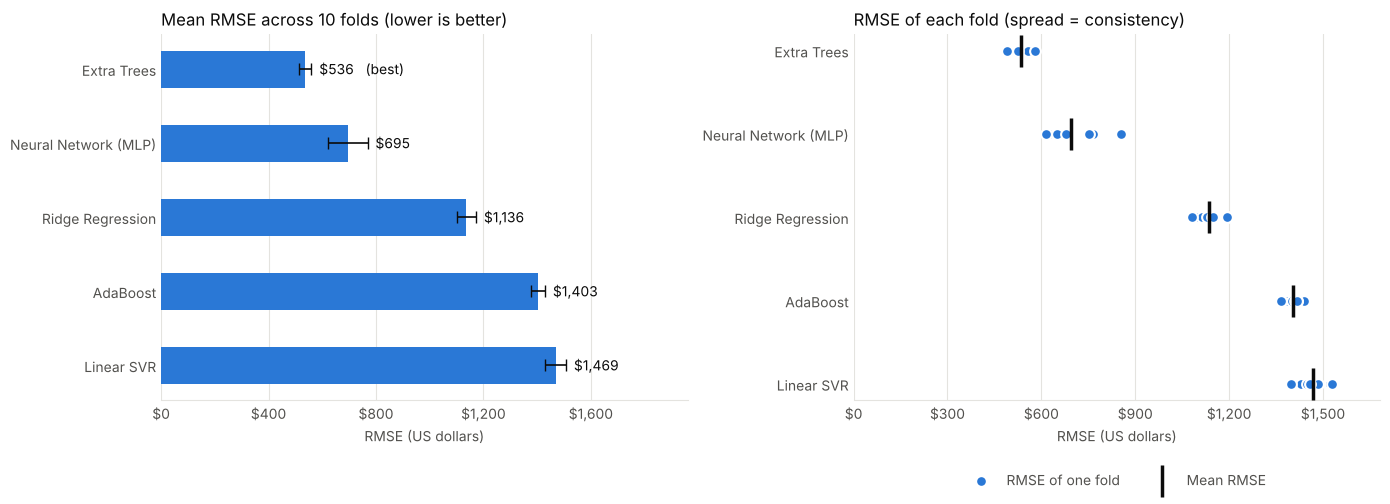

In [15]:
BAR_COLOR = "#2a78d6"
TEXT_COLOR = "#0b0b0b"
MUTED_TEXT = "#52514e"
GRID_COLOR = "#e4e3df"
dollars = FuncFormatter(lambda value, _: f"${value:,.0f}")

def style_axis(ax):
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID_COLOR)
    ax.tick_params(colors=MUTED_TEXT, length=0)
    ax.xaxis.set_major_formatter(dollars)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.grid(axis="x", color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)

order = summary.index.tolist()
positions = np.arange(len(order))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

means = summary["Mean RMSE ($)"]
stds = summary["Std RMSE ($)"]
ax1.barh(positions, means, height=0.5, color=BAR_COLOR,
         xerr=stds, error_kw=dict(ecolor=TEXT_COLOR, elinewidth=1.2, capsize=4))
for i, name in enumerate(order):
    label = f"${means[name]:,.0f}" + ("   (best)" if i == 0 else "")
    ax1.text(means[name] + stds[name] + means.max() * 0.02, i, label,
             va="center", color=TEXT_COLOR, fontsize=10)
ax1.set_yticks(positions, order, color=TEXT_COLOR)
ax1.invert_yaxis()
ax1.set_xlim(0, (means + stds).max() * 1.3)
style_axis(ax1)
ax1.set_title("Mean RMSE across 10 folds (lower is better)", loc="left", color=TEXT_COLOR, fontsize=12)
ax1.set_xlabel("RMSE (US dollars)", color=MUTED_TEXT)

for i, name in enumerate(order):
    ax2.scatter(per_fold_table[name], np.full(K, i), s=60, color=BAR_COLOR,
                edgecolor="white", linewidth=1.5, zorder=3,
                label="RMSE of one fold" if i == 0 else None)
    ax2.scatter(means[name], i, marker="|", s=500, color=TEXT_COLOR, linewidth=2.5, zorder=4,
                label="Mean RMSE" if i == 0 else None)
ax2.set_yticks(positions, order, color=TEXT_COLOR)
ax2.invert_yaxis()
ax2.set_xlim(0, per_fold_table.values.max() * 1.1)
style_axis(ax2)
ax2.set_title("RMSE of each fold (spread = consistency)", loc="left", color=TEXT_COLOR, fontsize=12)
ax2.set_xlabel("RMSE (US dollars)", color=MUTED_TEXT)
ax2.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, labelcolor=MUTED_TEXT)

plt.tight_layout()
plt.show()

## Step 9.4: Observations

> The numbers below come from our run. If your library versions or hardware are different, your numbers and especially the times may differ slightly, but the overall pattern should be the same.

1. **Extra Trees has the lowest mean RMSE (≈ $536)** and **won every one of the 10 folds**. Its typical error is about **13.6% of the average diamond price** (≈ $3,933), and its fold-to-fold standard deviation is only ≈ $24, so the result is both accurate and consistent.
2. **The Neural Network (MLP) is second (≈ $695)**. It also learns non-linear patterns, but it is the **least consistent** algorithm (standard deviation ≈ $74; folds range from ≈ $616 to ≈ $856), because its result depends on its random starting weights and on when early stopping ends training. It is also the **slowest** (≈ 4× slower than Extra Trees).
3. **Ridge Regression (≈ $1,136), AdaBoost (≈ $1,403) and Linear SVR (≈ $1,469) have two to three times the error of Extra Trees.** Diamond prices are **not linear**: a 2-carat diamond costs far more than two 1-carat diamonds, so a weighted sum of the features cannot fit the price curve well.
4. **AdaBoost is even worse than Ridge.** With its default settings it combines only 50 very shallow trees (depth 3), which split the price range into a small number of coarse steps.
5. **Linear SVR is the worst.** It ignores small errors inside its margin and penalises large errors less strongly than squared error does, so it is not optimised for RMSE.
6. **The comparison is very reliable.** Every algorithm's standard deviation is small (≤ ≈ $74) compared with the gaps between the algorithms. This is very different from the car data, where single cars worth over $1 million made the RMSE jump between folds: diamond prices have no extreme outliers and the folds are balanced (Step 7.2).
7. **Accuracy vs. speed:** Ridge Regression trains all 10 folds in about 1.5 seconds and is a useful baseline, but Extra Trees is about **2× more accurate** for about a minute of training, which is clearly worth it.

# Step 10: Train the Final Model
## Step 10.1: Select the Best Algorithm

Cross validation is used to **choose** an algorithm. The 10 models built during cross validation are now thrown away.

In [16]:
best_algorithm_name = summary.index[0]
best_mean_rmse = summary.loc[best_algorithm_name, "Mean RMSE ($)"]
best_std_rmse = summary.loc[best_algorithm_name, "Std RMSE ($)"]

print(f"Best algorithm : {best_algorithm_name}")
print(f"Expected RMSE  : ${best_mean_rmse:,.2f} (+/- ${best_std_rmse:,.2f})")

Best algorithm : Extra Trees
Expected RMSE  : $535.72 (+/- $23.71)


## Step 10.2: Train the Best Algorithm on All the Data

In [17]:
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", algorithms[best_algorithm_name]),
])
final_model.fit(X, y)
print(f"Final {best_algorithm_name} model trained on {len(X):,} diamonds.")

Final Extra Trees model trained on 53,794 diamonds.


## Step 10.3: Save the Trained Model and the Files Needed to Deploy It

The saved file contains the **whole pipeline** (imputer, scaler, one-hot encoder **and** the algorithm), so the web app can predict directly from raw diamond features. It is saved with `joblib` and bz2 compression, which keeps the file under 30 MB.

Two small files are saved next to the model and are used by the web app:

- `model_info.json`: the algorithm name, its cross-validation RMSE and the valid ranges of each input.
- `requirements.txt`: the **exact** library versions used to train this model. A saved scikit-learn model must be loaded with the same scikit-learn version, so the web app installs these versions.

To download the files in Colab, set `DOWNLOAD_FILES = True` and run the cell again, or use the **Files** panel on the left.

In [18]:
import json

MODEL_FILE = "diamond_price_model.joblib"
DOWNLOAD_FILES = False

joblib.dump(final_model, MODEL_FILE, compress=("bz2", 9))
print(f"Trained model saved as '{MODEL_FILE}' ({os.path.getsize(MODEL_FILE) / 1e6:.1f} MB)")

model_info = {
    "algorithm": best_algorithm_name,
    "cv_mean_rmse": round(float(best_mean_rmse), 2),
    "cv_std_rmse": round(float(best_std_rmse), 2),
    "folds": K,
    "training_rows": int(len(X)),
    "ranges": {c: [float(X[c].min()), float(X[c].max()), float(X[c].median())] for c in numeric_features},
    "categories": {
        "cut": ["Fair", "Good", "Very Good", "Premium", "Ideal"],
        "color": ["J", "I", "H", "G", "F", "E", "D"],
        "clarity": ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"],
    },
}
with open("model_info.json", "w") as f:
    json.dump(model_info, f, indent=2)

with open("requirements.txt", "w") as f:
    f.write(f"streamlit\nscikit-learn=={sklearn.__version__}\nnumpy=={np.__version__}\n"
            f"pandas=={pd.__version__}\njoblib=={joblib.__version__}\n")

print("Saved 'model_info.json' and 'requirements.txt':")
print(open("requirements.txt").read())

if IN_COLAB and DOWNLOAD_FILES:
    for name in [MODEL_FILE, "model_info.json", "requirements.txt"]:
        files.download(name)

Trained model saved as 'diamond_price_model.joblib' (28.3 MB)
Saved 'model_info.json' and 'requirements.txt':
streamlit
scikit-learn==1.9.1
numpy==2.5.3
pandas==3.0.5
joblib==1.6.0



# Step 11: Execute the Application Phase
## Step 11.1: Take Input from User

By default the notebook uses the example diamond below, so that **Run all** works without stopping. To type in your own diamond, set `USE_INTERACTIVE_INPUT = True` and run the cell again.

In [19]:
USE_INTERACTIVE_INPUT = False

example_diamond = {
    "carat": 0.9,
    "depth": 61.8,
    "table": 57.0,
    "x": 6.2,
    "y": 6.15,
    "z": 3.82,
    "cut": "Ideal",
    "color": "G",
    "clarity": "VS2",
}

def get_diamond_input():
    print("Enter Diamond Features (ranges seen in the data are shown):")
    diamond = {}
    for feature in numeric_features:
        low, high = X[feature].min(), X[feature].max()
        diamond[feature] = float(input(f"{feature} ({low:g} - {high:g}): "))
    for feature, options in model_info["categories"].items():
        diamond[feature] = input(f"{feature} {options}: ").strip()
    return diamond

user_input = get_diamond_input() if USE_INTERACTIVE_INPUT else example_diamond

print("Diamond features:")
for feature, value in user_input.items():
    print(f"  {feature:<8}: {value}")

Diamond features:
  carat   : 0.9
  depth   : 61.8
  table   : 57.0
  x       : 6.2
  y       : 6.15
  z       : 3.82
  cut     : Ideal
  color   : G
  clarity : VS2


## Step 11.2: Convert User Input into Feature Vector

In [20]:
feature_vector = pd.DataFrame([user_input])[numeric_features + categorical_features]
feature_vector

,carat,depth,table,x,y,z,cut,color,clarity
0,0.90,61.80,57.00,6.20,6.15,3.82,Ideal,G,VS2


## Step 11.3: Load the Saved Model

In [21]:
loaded_model = joblib.load(MODEL_FILE)
print(f"Model loaded from '{MODEL_FILE}': {loaded_model.named_steps['regressor'].__class__.__name__}")

Model loaded from 'diamond_price_model.joblib': ExtraTreesRegressor


## Step 11.4: Model Prediction

In [22]:
predicted_price = loaded_model.predict(feature_vector)[0]
print(f"Predicted Price: ${predicted_price:,.2f}")
print(f"Typical error (cross-validation RMSE of {best_algorithm_name}): about ${best_mean_rmse:,.0f}")

Predicted Price: $4,633.44
Typical error (cross-validation RMSE of Extra Trees): about $536


# Step 12: Model Deployment (Cloud + Web App)

The model is deployed as a **Streamlit web app** on **Streamlit Community Cloud** (free). The live link is at the very top of this notebook.

**How it works**

1. A GitHub repository contains four files: `app.py` (the web app), `diamond_price_model.joblib` (the model saved in Step 10.3), `model_info.json` and `requirements.txt`.
2. Streamlit Community Cloud installs the libraries listed in `requirements.txt` and runs `app.py` on its servers.
3. The user opens the link, chooses the carat, cut, colour, clarity and size of a diamond, and clicks **Predict Price**.
4. The app builds a feature vector in the same column order as Step 11.2, calls `model.predict()`, and shows the predicted price together with the cross-validation RMSE.

**The web app code (`app.py`)** is shown below for reference. It is a separate file and is not run inside this notebook.

```python
import json

import joblib
import pandas as pd
import streamlit as st

st.set_page_config(page_title="Diamond Price Predictor", page_icon="💎", layout="centered")


@st.cache_resource
def load_model():
    model = joblib.load("diamond_price_model.joblib")
    with open("model_info.json") as f:
        info = json.load(f)
    return model, info


model, info = load_model()
ranges = info["ranges"]
categories = info["categories"]

st.title("💎 Diamond Price Predictor")
st.write(
    f"Predicts the price of a diamond with a **{info['algorithm']}** model, chosen by "
    f"{info['folds']}-fold cross validation on {info['training_rows']:,} diamonds."
)

st.subheader("Diamond quality")
col1, col2, col3 = st.columns(3)
cut = col1.selectbox("Cut", categories["cut"], index=categories["cut"].index("Ideal"))
color = col2.selectbox("Colour (D = best)", categories["color"], index=categories["color"].index("G"))
clarity = col3.selectbox("Clarity (IF = best)", categories["clarity"], index=categories["clarity"].index("VS2"))

st.subheader("Size and shape")
carat = st.slider("Carat (weight)", float(ranges["carat"][0]), 3.0, 0.9, step=0.01)
col4, col5 = st.columns(2)
depth = col4.number_input("Depth (%)", float(ranges["depth"][0]), float(ranges["depth"][1]), 61.8, step=0.1)
table = col5.number_input("Table (%)", float(ranges["table"][0]), float(ranges["table"][1]), 57.0, step=0.5)
col6, col7, col8 = st.columns(3)
x = col6.number_input("Length x (mm)", 3.0, 11.0, 6.2, step=0.01)
y = col7.number_input("Width y (mm)", 3.0, 11.0, 6.15, step=0.01)
z = col8.number_input("Depth z (mm)", 1.0, 7.0, 3.82, step=0.01)

if st.button("Predict Price", type="primary", use_container_width=True):
    features = pd.DataFrame([{
        "carat": carat, "depth": depth, "table": table, "x": x, "y": y, "z": z,
        "cut": cut, "color": color, "clarity": clarity,
    }])
    price = float(model.predict(features)[0])
    st.metric("Predicted price", f"${price:,.0f}")
    st.caption(
        f"Typical error: about \\${info['cv_mean_rmse']:,.0f} "
        f"(cross-validation RMSE, ± \\${info['cv_std_rmse']:,.0f} across folds)."
    )

st.divider()
st.caption("AIC354 Machine Learning Fundamentals, Assignment 3 · Zain Aftab (FA24-BSE-155)")
```

# Step 13: Execute the Feedback Phase

After deployment, feedback from users and jewellers can be used to improve the model:

1. **Tune hyper-parameters**: the number of trees in Extra Trees, the hidden layer size of the Neural Network, or the regularisation strength of Ridge, chosen with cross validation (`GridSearchCV`).
2. **Predict the logarithm of the price**: prices grow much faster than carat weight, which particularly hurts the linear models.
3. **Report MAE as well as RMSE**, so users see the typical error in dollars.
4. **Collect newer data**: the dataset reflects prices from around 2008, so absolute prices are out of date.

# Conclusion

In this notebook we compared **5 regression algorithms** that were **not used in the Car Price Prediction System** on the **full diamonds dataset (53,794 unique diamonds)** using **10-fold cross validation** and **RMSE**.

| Rank | Algorithm | Mean RMSE | Std RMSE | RMSE as % of avg price |
|---|---|---|---|---|
| 1 | **Extra Trees** | **$536** | $24 | 13.6% |
| 2 | Neural Network (MLP) | $695 | $74 | 17.7% |
| 3 | Ridge Regression | $1,136 | $36 | 28.9% |
| 4 | AdaBoost | $1,403 | $26 | 35.7% |
| 5 | Linear SVR | $1,469 | $39 | 37.3% |

- **Extra Trees** achieved the lowest mean RMSE and won every fold. It was trained on all the diamonds, saved, used to predict the price of a new diamond, and **deployed as a web app** (link at the top of this notebook).
- **Non-linear models (Extra Trees, Neural Network) clearly beat the linear models (Ridge, Linear SVR)**, because diamond prices grow much faster than the features.
- Because the dataset is large and has no extreme price outliers, the 10-fold results are **stable**, so we can be confident in the ranking.